In [1]:
import os
import polars as pl

if not os.path.exists("datasets"):
    os.mkdir("datasets")

In [16]:
# Buscamos el nombre del archivo parquet del libro

book_file = [f for f in os.listdir("datasets") if "dataset_completo" in f and f.endswith(".parquet")][0]
path_book = os.path.join("datasets", book_file)

# Cargamos una vista previa
dataset_completo= pl.scan_parquet(path_book)

In [17]:
import polars as pl
import polars.selectors as cs

# 1. X_features: Todas las columnas MENOS las que empiezan por "label"
X_features = dataset_completo.select(~cs.starts_with("label"))

# 2. y_labels: SOLO las columnas que empiezan por "label"
y_labels = dataset_completo.select(cs.starts_with("label"))


In [18]:
def finalize_dataset(
    df_features: pl.DataFrame,
    df_labels: pl.DataFrame,
) -> pl.DataFrame:
    """Une features y labels y elimina los nulos generados por ventanas móviles.

    No aplicamos Z-score aquí: la normalización se hará más adelante,
    ajustando el StandardScaler SOLO con datos de entrenamiento de cada
    fold (y, para el modelo final, con todo el pool de CV), evitando así
    fuga de información (data leakage) hacia validación/test.
    """
    full_df = pl.concat([df_features, df_labels], how="horizontal")
    cleaned_df = full_df.drop_nulls()
    return cleaned_df


# Ensamblar y limpiar el dataset final
dataset_final = finalize_dataset(X_features, y_labels)

# Eliminamos columnas que no son features numéricas de entrada al modelo
dataset_final = dataset_final.drop([
    pl.col("mid_price_coordenada"),
    pl.col("^feat_.*$"),  # expresiones regulares nativas de Polars
])



In [40]:
dataset_final.collect().head(5)

v1,v2,v3,v4,v5,v6,v7,v8,v9,v10,v11,v12,v13,v14,v15,v16,v17,v18,v19,v20,v21,v22,v23,v24,v25,v26,v27,v28,v29,v30,v31,v32,v33,v34,v35,v36,v37,…,v113,v114,v115,v116,v117,v118,v119,v120,v121,v122,v123,v124,v125,v126,v127,v128,v129,v130,v131,v132,v133,v134,v135,v136,v137,v138,v139,v140,v141,v142,v143,OBI_Nivel_1,label_k_10,label_k_20,label_k_30,label_k_50,label_k_100
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32,i32,i32,i32,i32
68227.1,3.26,68227.0,6.072,68227.2,0.002,68226.9,0.001,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.0,0.036,0.1,87.754,1.5842e-14,0.1,186.658,5.9720e-12,0.1,636.747,6.4478e-12,0.301329,0,0,0,0,1
68227.1,3.209,68227.0,6.07,68227.2,0.002,68226.9,0.001,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,-0.051,-0.002,0.1,88.292,1.5842e-14,0.1,183.08,5.3311e-12,0.1,636.741,6.2780e-12,0.308331,0,0,0,0,1
68227.1,3.247,68227.0,6.07,68227.2,0.002,68226.9,0.003,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.038,0.0,0.1,89.45,1.5842e-14,0.1,180.303,4.4790e-12,0.1,638.501,6.0893e-12,0.302995,0,0,0,0,1
68227.1,3.274,68227.0,6.07,68227.2,0.002,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.027,0.0,0.1,92.905,1.5842e-14,0.1,177.553,3.2539e-12,0.1,640.428,5.8799e-12,0.299229,0,0,0,0,1
68227.1,3.418,68227.0,5.968,68227.2,0.002,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.144,-0.102,0.1,93.195,1.5842e-14,0.1,180.917,1.3373e-14,0.1,642.575,5.6474e-12,0.271681,0,0,0,0,1


In [6]:
pip install torchinfo

In [20]:
# ==========================================
# 1. Librerías
# ==========================================
import os
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from datetime import datetime
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils import data
from torchinfo import summary
import torch.optim as optim

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

In [8]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda:0


In [26]:
import os
import polars as pl
import numpy as np
import torch
from torch.utils import data

# ==========================================
# 2. Carga de datos ultra eficiente con Polars
# ==========================================
DATA_PATH = "dataset_completo.parquet"

if os.path.isfile(DATA_PATH):
    # Leemos solo las columnas necesarias para ahorrar aún más memoria
    df_pl = pl.read_parquet(DATA_PATH).head(1200000)
else:
    # Si viene del kernel, aseguramos que sea un DataFrame normal de Polars
    df_pl = dataset_final.head(1200000).collect() if hasattr(dataset_final, "collect") else dataset_final.head(1200000)

# ==========================================
# 3. Definición de columnas y splits cronológicos
# ==========================================
FEATURE_COLS = [f"v{i}" for i in range(1, 41)]
LABEL_COL = "label_k_100"

assert len(FEATURE_COLS) == 40, f"Se esperaban 144 features, hay {len(FEATURE_COLS)}"
missing = [c for c in FEATURE_COLS + [LABEL_COL] if c not in df_pl.columns]
assert not missing, f"Faltan columnas en el dataframe: {missing}"

# Ordenar si existe timestamp de manera eficiente
if "timestamp" in df_pl.columns:
    df_pl = df_pl.sort("timestamp")

print("Estructura inicial:", df_pl.shape)
print(df_pl[LABEL_COL].value_counts().sort(LABEL_COL))

# Splitting usando slicing nativo de Polars
TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

n = len(df_pl)
n_train = int(n * TRAIN_FRAC)
n_val = int(n * (TRAIN_FRAC + VAL_FRAC))

df_train = df_pl.slice(0, n_train)
df_val   = df_pl.slice(n_train, n_val - n_train)
df_test  = df_pl.slice(n_val, n - n_val)

print("Train:", df_train.shape, "Val:", df_val.shape, "Test:", df_test.shape)

# ==========================================
# 4. Normalización Z-score optimizada en Polars
# ==========================================
# Calculamos medias y desviaciones estándar sobre Train
stats = df_train.select([
    pl.col(FEATURE_COLS).mean().name.suffix("_mean"),
    pl.col(FEATURE_COLS).std().fill_null(1e-8).name.suffix("_std")
])

# Creamos las expresiones de normalización evitando división por cero
norm_exprs = [
    ((pl.col(col) - stats[0, f"{col}_mean"]) / (stats[0, f"{col}_std"] if stats[0, f"{col}_std"] != 0 else 1e-8)).alias(col)
    for col in FEATURE_COLS
] + [pl.col(LABEL_COL)] # conservamos el target intacto

# Aplicamos la transformación rápida de Polars y convertimos directamente a NumPy (Float32 para ahorrar RAM en PyTorch)
X_train = df_train.select(norm_exprs).select(FEATURE_COLS).to_numpy(writable=True).astype(np.float32)
Y_train = df_train[LABEL_COL].to_numpy().astype(np.int64)

X_val = df_val.select(norm_exprs).select(FEATURE_COLS).to_numpy(writable=True).astype(np.float32)
Y_val = df_val[LABEL_COL].to_numpy().astype(np.int64)

X_test = df_test.select(norm_exprs).select(FEATURE_COLS).to_numpy(writable=True).astype(np.float32)
Y_test = df_test[LABEL_COL].to_numpy().astype(np.int64)


# ==========================================
# 5. Dataset PyTorch Dinámico (Sin duplicación de memoria)
# ==========================================
class LOBDataset(data.Dataset):
    """
    Dataset optimizado. En lugar de guardar N ventanas precalculadas en memoria,
    extrae el fragmento temporal dinámicamente cuando el DataLoader lo solicita.
    """
    def __init__(self, X, Y, T):
        self.T = T
        self.X = torch.from_numpy(X)
        self.Y = torch.from_numpy(Y)
        # La cantidad de muestras válidas reales es N - T + 1
        self.length = len(X) - T + 1

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        # Extraemos la ventana de tamaño T empezando en el índice actual
        x_window = self.X[index : index + self.T]  # Shape: (T, D)
        # Añadimos la dimensión del canal para simular (1, T, D) requerido por la CNN de DeepLOB
        x_window = x_window.unsqueeze(0)

        # El target corresponde al último elemento de la ventana (horizonte T - 1 relativo al inicio)
        y_target = self.Y[index + self.T - 1]

        return x_window, y_target

T = 100
batch_size = 256
nw=4
dataset_train = LOBDataset(X_train, Y_train, T=T)
dataset_val   = LOBDataset(X_val, Y_val, T=T)
dataset_test  = LOBDataset(X_test, Y_test, T=T)

# DataLoaders idénticos a los tuyos (funcionarán perfectamente)
train_loader = data.DataLoader(dataset=dataset_train, batch_size=batch_size, shuffle=True)
val_loader   = data.DataLoader(dataset=dataset_val,   batch_size=batch_size, shuffle=False)
test_loader  = data.DataLoader(dataset=dataset_test,  batch_size=batch_size, shuffle=False)

# Reemplazo de compatibilidad para tus prints posteriores en el notebook
print(f"Train Dataset length: {len(dataset_train)} muestras indexables.")
print(f"Val Dataset length: {len(dataset_val)} muestras indexables.")
print(f"Test Dataset length: {len(dataset_test)} muestras indexables.")

Estructura inicial: (1200000, 149)
shape: (3, 2)
┌─────────────┬────────┐
│ label_k_100 ┆ count  │
│ ---         ┆ ---    │
│ i32         ┆ u32    │
╞═════════════╪════════╡
│ 0           ┆ 417088 │
│ 1           ┆ 358083 │
│ 2           ┆ 424829 │
└─────────────┴────────┘
Train: (840000, 149) Val: (180000, 149) Test: (180000, 149)
Train Dataset length: 839901 muestras indexables.
Val Dataset length: 179901 muestras indexables.
Test Dataset length: 179901 muestras indexables.


In [27]:
len(X_train[0])

40

In [28]:
class DeepLOB_CNNLSTM(nn.Module):
    # DeepLOB (Zhang et al., 2019) adaptado a un numero de features arbitrario (multiplo de 4)
    # y con funcion de activacion configurable (ELU / Tanh / LeakyReLU).

    def __init__(self, y_len, n_features=40, activation="elu"):
        super().__init__()
        self.y_len = y_len
        self.n_features = n_features

        assert n_features % 4 == 0, "n_features debe ser múltiplo de 4 (dos compresiones x2 antes del colapso final)."
        w_after_stride = n_features // 4   # ancho restante tras conv1 + conv2 (144 -> 72 -> 36)

        act = self._activation_cls(activation)

        # ---- Bloques convolucionales ----
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=(1, 2), stride=(1, 2)),
            act(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4, 1)),
            act(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4, 1)),
            act(),
            nn.BatchNorm2d(32),
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(1, 2), stride=(1, 2)),
            act(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4, 1)),
            act(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4, 1)),
            act(),
            nn.BatchNorm2d(32),
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(1, w_after_stride)),  # <- único cambio estructural
            act(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4, 1)),
            act(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4, 1)),
            act(),
            nn.BatchNorm2d(32),
        )

        # ---- Módulos inception ----
        self.inp1 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1, 1), padding="same"),
            act(),
            nn.BatchNorm2d(64),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3, 1), padding="same"),
            act(),
            nn.BatchNorm2d(64),
        )
        self.inp2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1, 1), padding="same"),
            act(),
            nn.BatchNorm2d(64),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(5, 1), padding="same"),
            act(),
            nn.BatchNorm2d(64),
        )
        self.inp3 = nn.Sequential(
            nn.MaxPool2d((3, 1), stride=(1, 1), padding=(1, 0)),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1, 1), padding="same"),
            act(),
            nn.BatchNorm2d(64),
        )

        # ---- LSTM + salida ----
        self.lstm = nn.LSTM(input_size=192, hidden_size=64, num_layers=1, batch_first=True)
        self.fc1 = nn.Linear(64, self.y_len)

    @staticmethod
    def _activation_cls(name):
        name = name.lower()
        if name == "elu":
            return nn.ELU
        elif name == "tanh":
            return nn.Tanh
        elif name == "leaky_relu":
            return lambda: nn.LeakyReLU(negative_slope=0.05)
        else:
            raise ValueError(f"Activación no soportada: {name!r}. Usa 'elu', 'tanh' o 'leaky_relu'.")

    def forward(self, x):
        h0 = torch.zeros(1, x.size(0), 64, device=x.device)
        c0 = torch.zeros(1, x.size(0), 64, device=x.device)

        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)

        x_inp1 = self.inp1(x)
        x_inp2 = self.inp2(x)
        x_inp3 = self.inp3(x)

        x = torch.cat((x_inp1, x_inp2, x_inp3), dim=1)

        x = x.permute(0, 2, 1, 3)
        x = torch.reshape(x, (-1, x.shape[1], x.shape[2]))

        x, _ = self.lstm(x, (h0, c0))
        x = x[:, -1, :]
        x = self.fc1(x)
        forecast_y = torch.softmax(x, dim=1)

        return forecast_y

In [29]:
# ACTIVATION: 'elu' o 'tanh' (o 'leaky_relu' para comparar con el original)
ACTIVATION = "leaky_relu"

model = DeepLOB_CNNLSTM(y_len=3, n_features=40, activation=ACTIVATION)
model.to(device)

summary(model, (1, 1, T, 40))

Layer (type:depth-idx)                   Output Shape              Param #
DeepLOB_CNNLSTM                          [1, 3]                    --
├─Sequential: 1-1                        [1, 32, 94, 20]           --
│    └─Conv2d: 2-1                       [1, 32, 100, 20]          96
│    └─LeakyReLU: 2-2                    [1, 32, 100, 20]          --
│    └─BatchNorm2d: 2-3                  [1, 32, 100, 20]          64
│    └─Conv2d: 2-4                       [1, 32, 97, 20]           4,128
│    └─LeakyReLU: 2-5                    [1, 32, 97, 20]           --
│    └─BatchNorm2d: 2-6                  [1, 32, 97, 20]           64
│    └─Conv2d: 2-7                       [1, 32, 94, 20]           4,128
│    └─LeakyReLU: 2-8                    [1, 32, 94, 20]           --
│    └─BatchNorm2d: 2-9                  [1, 32, 94, 20]           64
├─Sequential: 1-2                        [1, 32, 88, 10]           --
│    └─Conv2d: 2-10                      [1, 32, 94, 10]           2,080
│    └

In [30]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

##  Entrenamiento

Mismo bucle de entrenamiento (`batch_gd`) que el notebook original de DeepLOB, guardando el mejor modelo según pérdida de validación.

In [31]:
def batch_gd(model, criterion, optimizer, train_loader, val_loader, epochs, save_path="best_val_model_pytorch.pt"):
    train_losses = np.zeros(epochs)
    val_losses = np.zeros(epochs)
    best_val_loss = np.inf
    best_val_epoch = 0

    for it in tqdm(range(epochs)):
        model.train()
        t0 = datetime.now()
        train_loss = []
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device, dtype=torch.float), targets.to(device, dtype=torch.int64)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss.append(loss.item())
        train_loss = np.mean(train_loss)

        model.eval()
        val_loss = []
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device, dtype=torch.float), targets.to(device, dtype=torch.int64)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss.append(loss.item())
        val_loss = np.mean(val_loss)

        train_losses[it] = train_loss
        val_losses[it] = val_loss

        if val_loss < best_val_loss:
            torch.save(model, save_path)
            best_val_loss = val_loss
            best_val_epoch = it
            print("model saved")

        dt = datetime.now() - t0
        print(f"Epoch {it+1}/{epochs}, Train Loss: {train_loss:.4f}, "
              f"Val Loss: {val_loss:.4f}, Duration: {dt}, Best Val Epoch: {best_val_epoch}")

    return train_losses, val_losses

In [36]:
EPOCHS = 9

train_losses, val_losses = batch_gd(
    model, criterion, optimizer, train_loader, val_loader, epochs=EPOCHS
)

 11%|█         | 1/9 [04:22<35:01, 262.68s/it]

model saved
Epoch 1/9, Train Loss: 1.0108, Val Loss: 1.0387, Duration: 0:04:22.678395, Best Val Epoch: 0


 22%|██▏       | 2/9 [08:41<30:23, 260.44s/it]

Epoch 2/9, Train Loss: 1.0109, Val Loss: 1.0391, Duration: 0:04:18.878725, Best Val Epoch: 0


 33%|███▎      | 3/9 [13:00<25:58, 259.79s/it]

...

model saved
Epoch 7/9, Train Loss: 1.0109, Val Loss: 1.0383, Duration: 0:04:17.238678, Best Val Epoch: 6


 89%|████████▉ | 8/9 [34:31<04:18, 258.06s/it]

Epoch 8/9, Train Loss: 1.0108, Val Loss: 1.0384, Duration: 0:04:17.423031, Best Val Epoch: 6


100%|██████████| 9/9 [38:48<00:00, 258.73s/it]

Epoch 9/9, Train Loss: 1.0109, Val Loss: 1.0389, Duration: 0:04:17.517206, Best Val Epoch: 6


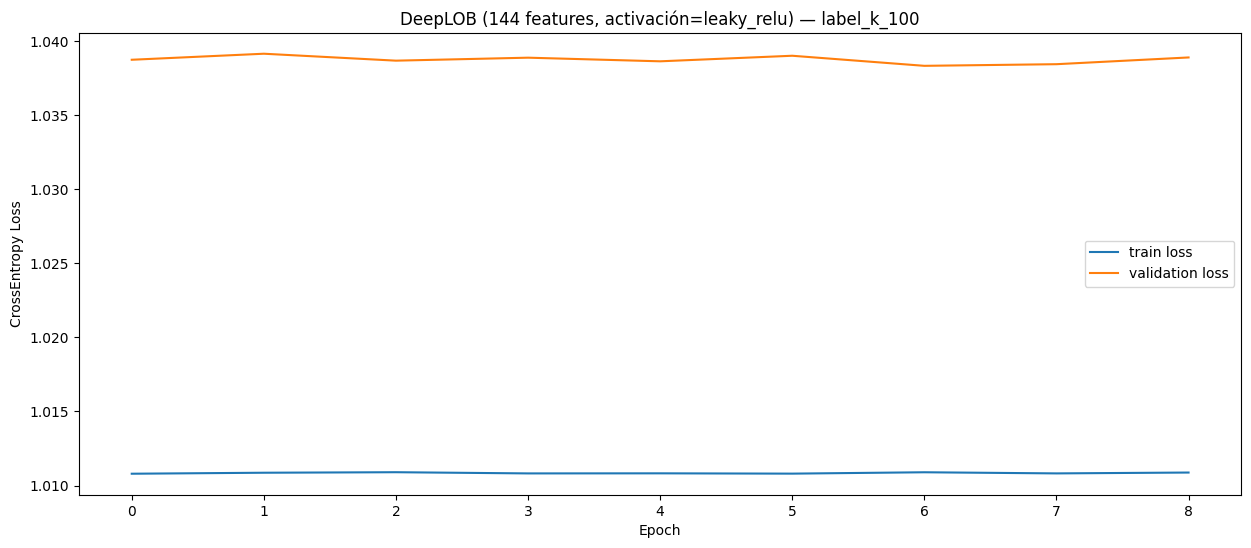

In [37]:
plt.figure(figsize=(15, 6))
plt.plot(train_losses, label="train loss")
plt.plot(val_losses, label="validation loss")
plt.legend()
plt.title(f"DeepLOB (144 features, activación={ACTIVATION}) — label_k_100")
plt.xlabel("Epoch")
plt.ylabel("CrossEntropy Loss")
plt.show()

##  Evaluación en test

Test accuracy con umbral: 0.36269948471659413

Reporte de Clasificación:
              precision    recall  f1-score   support

   Bajar (0)     0.6453    0.1002    0.1734     63883
 Neutral (1)     0.3145    0.8820    0.4637     53930
   Subir (2)     0.6021    0.1818    0.2793     62088

    accuracy                         0.3627    179901
   macro avg     0.5206    0.3880    0.3054    179901
weighted avg     0.5312    0.3627    0.2970    179901


Matriz de confusión (Numérica):
[[ 6399 54323  3161]
 [ 2068 47564  4298]
 [ 1449 49352 11287]]


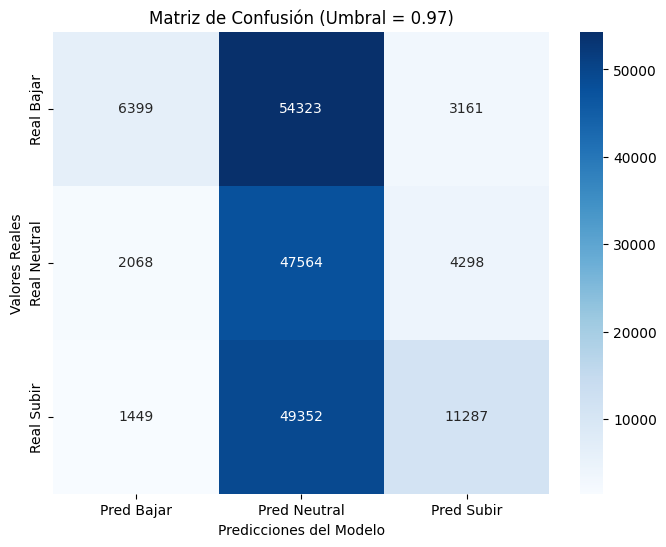

In [34]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

model = torch.load("best_val_model_pytorch.pt", weights_only=False)
model.eval()

all_targets = []
all_predictions = []

# ==========================================
# Configuración del Umbral de Confianza
# ==========================================
# Si el modelo no tiene al menos un 60% de seguridad en comprar (2) o vender (0),
# la predicción se forzará a ser Neutral (1).
CONFIDENCE_THRESHOLD = 0.97

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device, dtype=torch.float)
        targets = targets.to(device, dtype=torch.int64)

        # El modelo devuelve las probabilidades por clase (batch_size, 3)
        outputs = model(inputs)

        # Iteramos sobre cada muestra del lote (batch) para aplicar el umbral
        batch_predictions = []
        for prob in outputs:
            prob_bajar = prob[0].item()    # Clase 0
            prob_neutral = prob[1].item()  # Clase 1
            prob_subir = prob[2].item()    # Clase 2

            if prob_subir >= CONFIDENCE_THRESHOLD:
                pred = 2  # Compra (Alta confianza)
            elif prob_bajar >= CONFIDENCE_THRESHOLD:
                pred = 0  # Venta (Alta confianza)
            else:
                pred = 1  # Forzar a Neutral si no estamos seguros

            batch_predictions.append(pred)

        all_targets.append(targets.cpu().numpy())
        all_predictions.append(np.array(batch_predictions))

all_targets = np.concatenate(all_targets)
all_predictions = np.concatenate(all_predictions)

# ==========================================
# Visualización de Métricas y Matriz de Confusión
# ==========================================
print("Test accuracy con umbral:", accuracy_score(all_targets, all_predictions))
print("\nReporte de Clasificación:")
print(classification_report(all_targets, all_predictions, digits=4, target_names=["Bajar (0)", "Neutral (1)", "Subir (2)"]))

# Calcular la matriz de confusión numérica
cm = confusion_matrix(all_targets, all_predictions)
print("\nMatriz de confusión (Numérica):")
print(cm)

# Graficar la matriz de confusión de forma visual y profesional con Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Bajar", "Pred Neutral", "Pred Subir"],
            yticklabels=["Real Bajar", "Real Neutral", "Real Subir"])
plt.ylabel('Valores Reales')
plt.xlabel('Predicciones del Modelo')
plt.title(f'Matriz de Confusión (Umbral = {CONFIDENCE_THRESHOLD})')
plt.show()

In [35]:
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix

# Asegurar que el dispositivo esté configurado
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Cargar el modelo de PyTorch
model = torch.load("best_val_model_pytorch.pt", weights_only=False)
model.to(device)
model.eval()

all_targets = []
all_raw_outputs = []  # Guardaremos las probabilidades crudas aquí

# ==========================================
# EXTRAER PROBABILIDADES EN UNA SOLA PASADA
# ==========================================
print("🧠 Extrayendo probabilidades del modelo sobre el Test Loader...")
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device, dtype=torch.float)

        # El modelo devuelve las probabilidades por clase (batch_size, 3)
        outputs = model(inputs)

        all_targets.append(targets.numpy())  # test_loader suele dar targets en CPU
        all_raw_outputs.append(outputs.cpu().numpy())

all_targets = np.concatenate(all_targets)
preds_prob_torch = np.concatenate(all_raw_outputs)

# Separamos las columnas de probabilidad para operar más rápido con NumPy (sin bucles for por muestra)
prob_bajar = preds_prob_torch[:, 0]
prob_subir = preds_prob_torch[:, 2]

# ==========================================
# EVALUACIÓN MULTI-UMBRAL (45% a 80%)
# ==========================================
print("\n🔄 Generando reportes completos para diferentes umbrales de confianza...")

# Definir los umbrales desde 0.45 hasta 0.80 de 5 en 5
umbrales = np.arange(0.75, 1.00, 0.05)

for u in umbrales:
    print("\n" + "="*80)
    print(f"🎯 EVALUACIÓN CON UMBRAL DE CONFIANZA: {u:.2f}")
    print("="*80)

    # Inicializar todas las predicciones como Neutral (1)
    y_pred_u = np.ones(len(preds_prob_torch), dtype=int)

    # Aplicación vectorizada con NumPy (infinitamente más rápida que iterar fila por fila)
    y_pred_u[prob_bajar >= u] = 0  # Bajar (Venta)
    y_pred_u[prob_subir >= u] = 2  # Subir (Compra)

    print(f"\n📊 REPORTE DE CLASIFICACIÓN FINAL REAL (Sobre Datos Ciegos - Umbral {u:.2f}):")
    print(classification_report(all_targets, y_pred_u, target_names=["Bajar (0)", "Neutral (1)", "Subir (2)"], zero_division=0, digits=4))

    print(f"🧮 MATRIZ DE CONFUSIÓN REAL (Umbral {u:.2f}):")
    cm = confusion_matrix(all_targets, y_pred_u)
    print(cm)

    # Calcular el grado de actividad operativa en el LOB
    ticks_operados = np.sum((y_pred_u == 0) | (y_pred_u == 2))
    pct_operado = (ticks_operados / len(all_targets)) * 100
    print(f"\n📈 Grado de actividad en mercado: {pct_operado:.2f}% de los ticks operados.")


🧠 Extrayendo probabilidades del modelo sobre el Test Loader...

🔄 Generando reportes completos para diferentes umbrales de confianza...

🎯 EVALUACIÓN CON UMBRAL DE CONFIANZA: 0.75

📊 REPORTE DE CLASIFICACIÓN FINAL REAL (Sobre Datos Ciegos - Umbral 0.75):
              precision    recall  f1-score   support

   Bajar (0)     0.5755    0.2977    0.3924     63883
 Neutral (1)     0.3385    0.6511    0.4454     53930
   Subir (2)     0.5449    0.3783    0.4466     62088

    accuracy                         0.4315    179901
   macro avg     0.4863    0.4424    0.4282    179901
weighted avg     0.4939    0.4315    0.4270    179901

🧮 MATRIZ DE CONFUSIÓN REAL (Umbral 0.75):
[[19020 35913  8950]
 [ 8145 35116 10669]
 [ 5887 32711 23490]]

📈 Grado de actividad en mercado: 42.33% de los ticks operados.

🎯 EVALUACIÓN CON UMBRAL DE CONFIANZA: 0.80

📊 REPORTE DE CLASIFICACIÓN FINAL REAL (Sobre Datos Ciegos - Umbral 0.80):
              precision    recall  f1-score   support

   Bajar (0)     0.5

Test accuracy con umbral: 0.3580580430347802

Reporte de Clasificación:
              precision    recall  f1-score   support

   Bajar (0)     0.6538    0.0925    0.1621     63883
 Neutral (1)     0.3136    0.8944    0.4644     53930
   Subir (2)     0.6020    0.1654    0.2595     62088

    accuracy                         0.3581    179901
   macro avg     0.5231    0.3841    0.2953    179901
weighted avg     0.5339    0.3581    0.2863    179901


Matriz de confusión (Numérica):
[[ 5910 55057  2916]
 [ 1821 48234  3875]
 [ 1309 50508 10271]]


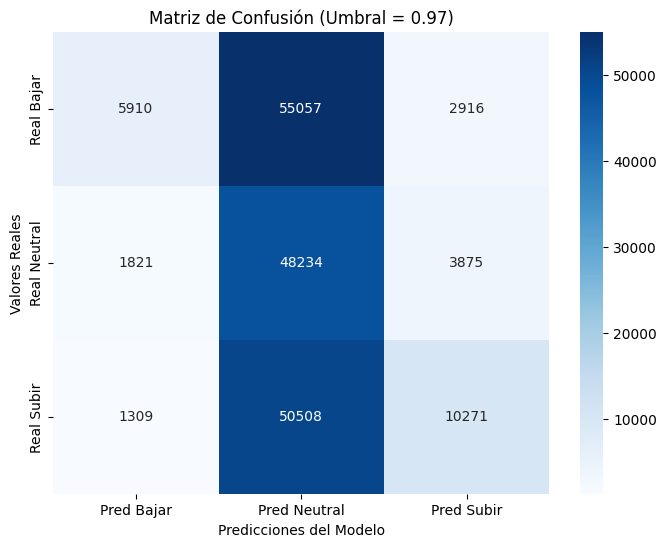

In [38]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

model = torch.load("best_val_model_pytorch.pt", weights_only=False)
model.eval()

all_targets = []
all_predictions = []

# ==========================================
# Configuración del Umbral de Confianza
# ==========================================
# Si el modelo no tiene al menos un 60% de seguridad en comprar (2) o vender (0),
# la predicción se forzará a ser Neutral (1).
CONFIDENCE_THRESHOLD = 0.97

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device, dtype=torch.float)
        targets = targets.to(device, dtype=torch.int64)

        # El modelo devuelve las probabilidades por clase (batch_size, 3)
        outputs = model(inputs)

        # Iteramos sobre cada muestra del lote (batch) para aplicar el umbral
        batch_predictions = []
        for prob in outputs:
            prob_bajar = prob[0].item()    # Clase 0
            prob_neutral = prob[1].item()  # Clase 1
            prob_subir = prob[2].item()    # Clase 2

            if prob_subir >= CONFIDENCE_THRESHOLD:
                pred = 2  # Compra (Alta confianza)
            elif prob_bajar >= CONFIDENCE_THRESHOLD:
                pred = 0  # Venta (Alta confianza)
            else:
                pred = 1  # Forzar a Neutral si no estamos seguros

            batch_predictions.append(pred)

        all_targets.append(targets.cpu().numpy())
        all_predictions.append(np.array(batch_predictions))

all_targets = np.concatenate(all_targets)
all_predictions = np.concatenate(all_predictions)

# ==========================================
# Visualización de Métricas y Matriz de Confusión
# ==========================================
print("Test accuracy con umbral:", accuracy_score(all_targets, all_predictions))
print("\nReporte de Clasificación:")
print(classification_report(all_targets, all_predictions, digits=4, target_names=["Bajar (0)", "Neutral (1)", "Subir (2)"]))

# Calcular la matriz de confusión numérica
cm = confusion_matrix(all_targets, all_predictions)
print("\nMatriz de confusión (Numérica):")
print(cm)

# Graficar la matriz de confusión de forma visual y profesional con Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Bajar", "Pred Neutral", "Pred Subir"],
            yticklabels=["Real Bajar", "Real Neutral", "Real Subir"])
plt.ylabel('Valores Reales')
plt.xlabel('Predicciones del Modelo')
plt.title(f'Matriz de Confusión (Umbral = {CONFIDENCE_THRESHOLD})')
plt.show()

In [41]:
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix

# Asegurar que el dispositivo esté configurado
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Cargar el modelo de PyTorch
model = torch.load("best_val_model_pytorch.pt", weights_only=False)
model.to(device)
model.eval()

all_targets = []
all_raw_outputs = []  # Guardaremos las probabilidades crudas aquí

# ==========================================
# EXTRAER PROBABILIDADES EN UNA SOLA PASADA
# ==========================================
print("🧠 Extrayendo probabilidades del modelo sobre el Test Loader...")
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device, dtype=torch.float)

        # El modelo devuelve las probabilidades por clase (batch_size, 3)
        outputs = model(inputs)

        all_targets.append(targets.numpy())  # test_loader suele dar targets en CPU
        all_raw_outputs.append(outputs.cpu().numpy())

all_targets = np.concatenate(all_targets)
preds_prob_torch = np.concatenate(all_raw_outputs)

# Separamos las columnas de probabilidad para operar más rápido con NumPy (sin bucles for por muestra)
prob_bajar = preds_prob_torch[:, 0]
prob_subir = preds_prob_torch[:, 2]

# ==========================================
# EVALUACIÓN MULTI-UMBRAL (45% a 80%)
# ==========================================
print("\n🔄 Generando reportes completos para diferentes umbrales de confianza...")

# Definir los umbrales desde 0.45 hasta 0.80 de 5 en 5
umbrales = np.arange(0.75, 1.00, 0.05)

for u in umbrales:
    print("\n" + "="*80)
    print(f"🎯 EVALUACIÓN CON UMBRAL DE CONFIANZA: {u:.2f}")
    print("="*80)

    # Inicializar todas las predicciones como Neutral (1)
    y_pred_u = np.ones(len(preds_prob_torch), dtype=int)

    # Aplicación vectorizada con NumPy (infinitamente más rápida que iterar fila por fila)
    y_pred_u[prob_bajar >= u] = 0  # Bajar (Venta)
    y_pred_u[prob_subir >= u] = 2  # Subir (Compra)

    print(f"\n📊 REPORTE DE CLASIFICACIÓN FINAL REAL (Sobre Datos Ciegos - Umbral {u:.2f}):")
    print(classification_report(all_targets, y_pred_u, target_names=["Bajar (0)", "Neutral (1)", "Subir (2)"], zero_division=0, digits=4))

    print(f"🧮 MATRIZ DE CONFUSIÓN REAL (Umbral {u:.2f}):")
    cm = confusion_matrix(all_targets, y_pred_u)
    print(cm)

    # Calcular el grado de actividad operativa en el LOB
    ticks_operados = np.sum((y_pred_u == 0) | (y_pred_u == 2))
    pct_operado = (ticks_operados / len(all_targets)) * 100
    print(f"\n📈 Grado de actividad en mercado: {pct_operado:.2f}% de los ticks operados.")


🧠 Extrayendo probabilidades del modelo sobre el Test Loader...

🔄 Generando reportes completos para diferentes umbrales de confianza...

🎯 EVALUACIÓN CON UMBRAL DE CONFIANZA: 0.75

📊 REPORTE DE CLASIFICACIÓN FINAL REAL (Sobre Datos Ciegos - Umbral 0.75):
              precision    recall  f1-score   support

   Bajar (0)     0.5760    0.2923    0.3879     63883
 Neutral (1)     0.3377    0.6551    0.4456     53930
   Subir (2)     0.5435    0.3751    0.4439     62088

    accuracy                         0.4297    179901
   macro avg     0.4858    0.4409    0.4258    179901
weighted avg     0.4934    0.4297    0.4245    179901

🧮 MATRIZ DE CONFUSIÓN REAL (Umbral 0.75):
[[18676 36292  8915]
 [ 7957 35332 10641]
 [ 5788 33013 23287]]

📈 Grado de actividad en mercado: 41.84% de los ticks operados.

🎯 EVALUACIÓN CON UMBRAL DE CONFIANZA: 0.80

📊 REPORTE DE CLASIFICACIÓN FINAL REAL (Sobre Datos Ciegos - Umbral 0.80):
              precision    recall  f1-score   support

   Bajar (0)     0.5

In [45]:
dataset_completo = dataset_completo.with_columns(
    ((pl.col("v1") + pl.col("v3")) / 2).alias("mid_price_coordenada")
)

In [46]:
dataset_completo.collect().head(5)

v1,v2,v3,v4,v5,v6,v7,v8,v9,v10,v11,v12,v13,v14,v15,v16,v17,v18,v19,v20,v21,v22,v23,v24,v25,v26,v27,v28,v29,v30,v31,v32,v33,v34,v35,v36,v37,…,v114,v115,v116,v117,v118,v119,v120,v121,v122,v123,v124,v125,v126,v127,v128,v129,v130,v131,v132,v133,v134,v135,v136,v137,v138,v139,v140,v141,v142,v143,mid_price_coordenada,OBI_Nivel_1,label_k_10,label_k_20,label_k_30,label_k_50,label_k_100
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32,i32,i32,i32,i32
68227.1,3.26,68227.0,6.072,68227.2,0.002,68226.9,0.001,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.0,0.036,0.1,87.754,1.5842e-14,0.1,186.658,5.9720e-12,0.1,636.747,6.4478e-12,68227.05,0.301329,0,0,0,0,1
68227.1,3.209,68227.0,6.07,68227.2,0.002,68226.9,0.001,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,-0.051,-0.002,0.1,88.292,1.5842e-14,0.1,183.08,5.3311e-12,0.1,636.741,6.2780e-12,68227.05,0.308331,0,0,0,0,1
68227.1,3.247,68227.0,6.07,68227.2,0.002,68226.9,0.003,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.038,0.0,0.1,89.45,1.5842e-14,0.1,180.303,4.4790e-12,0.1,638.501,6.0893e-12,68227.05,0.302995,0,0,0,0,1
68227.1,3.274,68227.0,6.07,68227.2,0.002,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.027,0.0,0.1,92.905,1.5842e-14,0.1,177.553,3.2539e-12,0.1,640.428,5.8799e-12,68227.05,0.299229,0,0,0,0,1
68227.1,3.418,68227.0,5.968,68227.2,0.002,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.144,-0.102,0.1,93.195,1.5842e-14,0.1,180.917,1.3373e-14,0.1,642.575,5.6474e-12,68227.05,0.271681,0,0,0,0,1


In [82]:
import numpy as np

# --- Parámetros de la simulación ---
ts = 0.85          # Umbral de confianza operativo (dentro del rango [0.75, 0.95] de la Sección 4.6.4)
fee = 0.0000       # Comisión/deslizamiento fijo por operación (idéntico al usado en el backtest de XGBoost)

assert 0.0 < ts < 1.0, "El umbral 'ts' debe estar en (0, 1)."

# --- Reconstrucción de las señales de DeepLOB al umbral operativo 'ts' ---
# prob_bajar, prob_subir y all_targets deben existir en memoria (celda de extracción
# de probabilidades del notebook de entrenamiento de DeepLOB).
y_pred_custom = np.ones(len(all_targets), dtype=int)   # 1 = Neutral por defecto
y_pred_custom[prob_bajar >= ts] = 0                      # Señal de venta (DOWN)
y_pred_custom[prob_subir >= ts] = 2                      # Señal de compra (UP)

n_señales = int((y_pred_custom != 1).sum())
print(f"Umbral operativo ts = {ts:.2f}")
print(f"Señales direccionales: {n_señales} de {len(y_pred_custom)} "
      f"({n_señales / len(y_pred_custom) * 100:.2f}% de actividad en mercado)")

# --- Alineación del mid-price con las ventanas deslizantes de DeepLOB ---
precios_completos = df_test.select("v1").to_numpy().flatten()
precios = precios_completos[T - 1:]

assert len(precios) == len(y_pred_custom), (
    f"Desalineación: precios={len(precios)} vs. predicciones={len(y_pred_custom)}. "
    "Revisa que 'T' y 'df_test' coincidan con los usados al construir 'dataset_test'."
)
print(f"Vector de precios alineado correctamente: {len(precios)} observaciones.")

Umbral operativo ts = 0.85
Señales direccionales: 54398 de 179901 (30.24% de actividad en mercado)
Vector de precios alineado correctamente: 179901 observaciones.


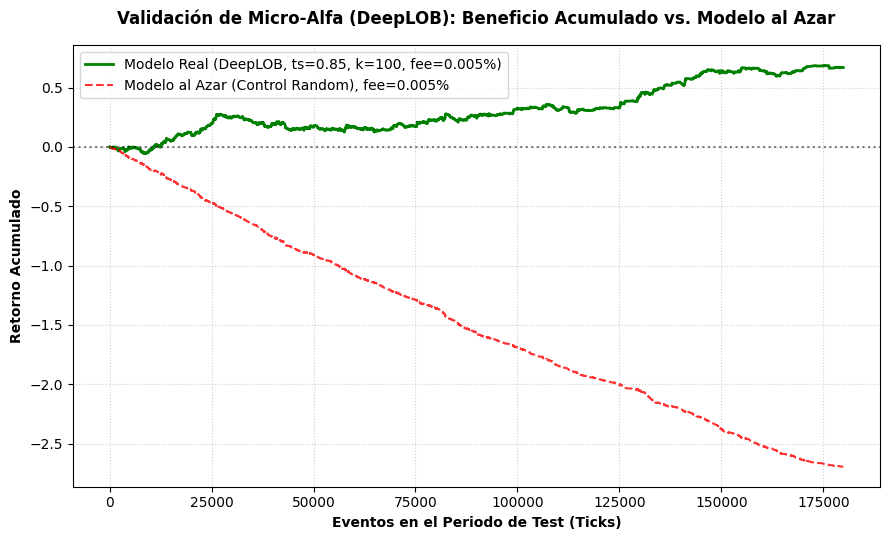

Retorno acumulado final (Real):  0.66893
Retorno acumulado final (Azar):  -2.69477


In [84]:
import matplotlib.pyplot as plt

np.random.seed(42)  # reproducibilidad del control aleatorio

k = 100  # horizonte de evaluación del retorno futuro (coincide con label_k_100)

# Retorno futuro real del precio a k ticks vista
retorno_futuro = np.zeros(len(precios))
retorno_futuro[:-k] = (precios[k:] - precios[:-k]) / precios[:-k]

# --- Estrategia DeepLOB real ---
beneficios_real = np.zeros(len(precios))
beneficios_real[y_pred_custom == 2] = retorno_futuro[y_pred_custom == 2] - fee
beneficios_real[y_pred_custom == 0] = -retorno_futuro[y_pred_custom == 0] - fee
cum_profit_real = np.cumsum(beneficios_real)

# --- Estrategia al azar (mismo volumen de operativa, orden mezclado) ---
y_pred_azar = y_pred_custom.copy()
indices_operativos = np.where((y_pred_custom == 0) | (y_pred_custom == 2))[0]
etiquetas_operativas_mezcladas = y_pred_custom[indices_operativos].copy()
np.random.shuffle(etiquetas_operativas_mezcladas)
y_pred_azar[indices_operativos] = etiquetas_operativas_mezcladas

beneficios_azar = np.zeros(len(precios))
beneficios_azar[y_pred_azar == 2] = retorno_futuro[y_pred_azar == 2] - fee
beneficios_azar[y_pred_azar == 0] = -retorno_futuro[y_pred_azar == 0] - fee
cum_profit_azar = np.cumsum(beneficios_azar)

# --- Gráfico ---
plt.figure(figsize=(9, 5.5))
plt.plot(cum_profit_real, color="green", linewidth=2, label=f"Modelo Real (DeepLOB, ts={ts:.2f}, k={k}, fee={fee*100}%)")
plt.plot(cum_profit_azar, color="red", linestyle="--", alpha=0.8, label=f"Modelo al Azar (Control Random), fee={fee*100}%")
plt.title("Validación de Micro-Alfa (DeepLOB): Beneficio Acumulado vs. Modelo al Azar",
          fontsize=12, fontweight="bold", pad=15)
plt.xlabel("Eventos en el Periodo de Test (Ticks)", fontweight="bold")
plt.ylabel("Retorno Acumulado", fontweight="bold")
plt.axhline(0, color="black", linestyle=":", alpha=0.5)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Retorno acumulado final (Real):  {cum_profit_real[-1]:.5f}")
print(f"Retorno acumulado final (Azar):  {cum_profit_azar[-1]:.5f}")